**TODO:** Clean this up

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
MANIFEST_PATH = "../data/fleurs/train_manifest.json"

rows = []
with open(MANIFEST_PATH, encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            rows.append(json.loads(line))

In [4]:
df = pd.DataFrame(rows)

df["text_len"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()
df["chars_per_sec"] = df["text_len"] / df["duration"]

print(f"{len(df)} utterances, {df['duration'].sum() / 3600:.2f} hours total")
df[["text_len", "word_count", "duration", "chars_per_sec"]].describe()

1599 utterances, 6.88 hours total


,text_len,word_count,duration,chars_per_sec
count,1599.000000,1599.000000,1599.000000,1599.000000
mean,174.285178,25.001251,15.479512,11.459838
std,61.879652,8.727196,5.516072,2.184414
min,39.000000,6.000000,3.480000,5.413105
25%,129.000000,19.000000,11.610000,9.850578
50%,168.000000,24.000000,14.640000,11.352657
75%,213.000000,30.000000,18.780000,12.732200
max,463.000000,64.000000,37.320000,21.849593


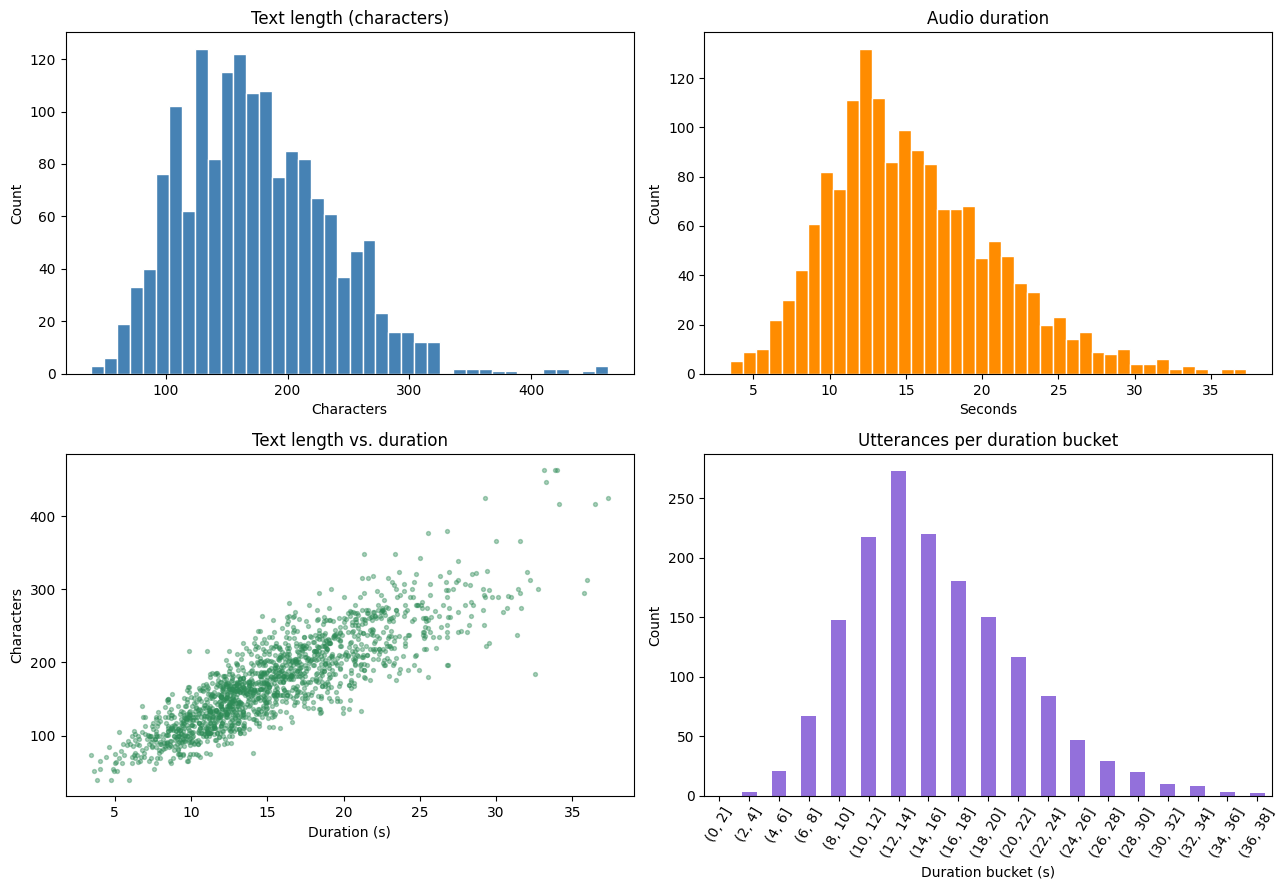

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].hist(df["text_len"], bins=40, color="steelblue", edgecolor="white")
axes[0, 0].set_title("Text length (characters)")
axes[0, 0].set_xlabel("Characters")
axes[0, 0].set_ylabel("Count")

axes[0, 1].hist(df["duration"], bins=40, color="darkorange", edgecolor="white")
axes[0, 1].set_title("Audio duration")
axes[0, 1].set_xlabel("Seconds")
axes[0, 1].set_ylabel("Count")

axes[1, 0].scatter(df["duration"], df["text_len"], s=8, alpha=0.4, color="seagreen")
axes[1, 0].set_title("Text length vs. duration")
axes[1, 0].set_xlabel("Duration (s)")
axes[1, 0].set_ylabel("Characters")

bucket = pd.cut(df["duration"], bins=range(0, int(df["duration"].max()) + 3, 2))
bucket.value_counts().sort_index().plot.bar(ax=axes[1, 1], color="mediumpurple")
axes[1, 1].set_title("Utterances per duration bucket")
axes[1, 1].set_xlabel("Duration bucket (s)")
axes[1, 1].set_ylabel("Count")
axes[1, 1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()